# MIT Academy of Engineering, Alandi, Pune
## Department of Computer Science and Engineering (AI & ML)
### T.Y. B.Tech | Generative AI Lab

# Practical No. 06
## Retrieval-Augmented Generation (RAG) Using a Pre-trained LLM

### Student Information
- **Name of Student:** Shreya Dattaram Bhosale
- **PRN Number:** Enter your PRN
- **Batch:** A3
- **Date of Submission:** 04 November 2026

---

## 1. Objective

To develop a Retrieval-Augmented Generation (RAG) application that answers questions from a domain-specific collection of educational documents about **Future India 2047**.

The practical implements document loading, cleaning, chunking, embedding generation, vector indexing, semantic retrieval and answer generation using a pre-trained Large Language Model (LLM). It also compares RAG responses with responses generated by the same LLM without retrieval.

## 2. Problem Definition

### 2.1 Background and problem statement

India's development towards 2047 involves several connected areas, including digital infrastructure, smart and sustainable cities, clean energy, modern transportation, healthcare, education and agricultural innovation. Information about these areas is distributed across government initiatives, policy documents and public information resources.

A general-purpose LLM may provide broad answers, but those answers may not be grounded in a selected collection of reference documents. This practical builds a question-answering system that retrieves relevant passages from a focused Future India knowledge collection and supplies them to a pre-trained LLM before answer generation.

### 2.2 Scope and document collection

The knowledge collection covers:
1. India's Vision 2047 and inclusive development.
2. Digital India and digital public infrastructure.
3. Smart cities and sustainable urban development.
4. Renewable energy and green hydrogen.
5. Modern transportation and logistics.
6. Healthcare, education and agricultural technology.

The notebook uses concise educational notes prepared as a learning knowledge base, with official public resources listed in the source register. The notes are summaries and do not replace the original policies, scheme guidelines or official publications.

## 3. Methodology

### 3.1 Tools and models

| Component | Technology | Purpose |
|---|---|---|
| Programming language | Python | Implementation |
| Embedding model | `sentence-transformers/all-MiniLM-L6-v2` | Convert document chunks and queries into vectors |
| Vector index | FAISS `IndexFlatIP` | Store embeddings and perform nearest-neighbour retrieval |
| Pre-trained LLM | `google/flan-t5-small` | Generate answers from prompts |
| Similarity measure | Cosine similarity | Rank relevant chunks |
| Evaluation | Hit@k, MRR, token F1, keyword coverage and latency | Assess retrieval and answer behavior |

**Model selection:** MiniLM is a compact sentence-embedding model suitable for semantic retrieval in a small corpus. FAISS exact inner-product search is appropriate for a practical-sized collection; normalized vectors make inner product equivalent to cosine similarity. FLAN-T5-small is selected to keep inference manageable on a student laptop or Colab CPU. The same LLM is used for RAG and baseline comparison to keep the comparison controlled.

### 3.2 RAG architecture

```text
FUTURE INDIA REFERENCE DOCUMENTS
              |
              v
       Load, clean and chunk
              |
              v
    Sentence-transformer embeddings
              |
              v
          FAISS index <------------- User question
              |                            |
              |                       Query embedding
              |                            |
              +------ Similarity search ---+
                            |
                            v
                  Top-k relevant chunks
                            |
                            v
                   Pre-trained LLM
                            |
                            v
                     RAG answer

User question ----------------> Same LLM without context
                                      |
                                      v
                                LLM-only answer

                       Compare both responses
```

### 3.3 Source register

The following official public resources provide background for the educational notes in this notebook:

1. NITI Aayog — [Strategy for New India @ 75](https://www.niti.gov.in/).
2. Ministry of Electronics and Information Technology — [Digital India](https://www.digitalindia.gov.in/).
3. Ministry of Housing and Urban Affairs — [Smart Cities Mission](https://smartcities.gov.in/).
4. Ministry of New and Renewable Energy — [National Green Hydrogen Mission](https://mnre.gov.in/).
5. Ministry of Road Transport and Highways — [Government of India](https://morth.nic.in/).
6. Ministry of Health and Family Welfare — [Ayushman Bharat Digital Mission](https://abdm.gov.in/).
7. Ministry of Education — [National Education Policy 2020](https://www.education.gov.in/nep/about-nep).
8. Ministry of Agriculture and Farmers Welfare — [Government of India](https://agriwelfare.gov.in/).

The notebook contains short educational summaries for demonstration. Consult the official sources for current scheme details, eligibility, targets and policy updates.

### 3.4 Environment setup

Run the notebook sequentially in Google Colab or a local Python environment with internet access for first-time model downloads. The first execution downloads the embedding model and LLM and may take several minutes.

In [1]:
%pip -q install -U sentence-transformers transformers accelerate faiss-cpu

In [2]:
import os
import re
import time
import textwrap
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import faiss

from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Execution device:", DEVICE)
print("FAISS version:", faiss.__version__)

Execution device: cpu
FAISS version: 1.15.1


### 3.5 Document loading and cleaning

For reproducibility, the notebook creates six separate local text files containing concise educational notes about Future India 2047. Each file represents a distinct topic. The source register above identifies official public resources for further reading.

In [3]:
DOCUMENTS_DIR = "future_india_rag_knowledge_base"
os.makedirs(DOCUMENTS_DIR, exist_ok=True)

documents = {
    "01_vision_2047_and_inclusive_development.txt": """
Future India 2047 and inclusive development.
India's development vision towards 2047 focuses on a prosperous, inclusive, capable and developed nation. Development involves economic opportunity, quality public services, infrastructure, innovation, environmental sustainability and citizen participation.
Inclusive development aims to ensure that opportunities reach people across regions, genders, income groups and communities. Access to education, healthcare, skills, clean water, sanitation, reliable energy and digital services supports human development.
Long-term development requires coordination between central, state and local institutions, private organisations, research institutions and citizens. Transparent governance, effective public service delivery and evidence-based planning are important.
Progress should be assessed using measurable outcomes such as access, quality, affordability, resilience, employment and environmental impact rather than technology adoption alone.
The 2047 vision is a broad national aspiration. Specific programme targets, timelines and eligibility conditions must be checked in current official government documents.
""",
    "02_digital_india_and_public_infrastructure.txt": """
Digital India and digital public infrastructure.
Digital India is a Government of India programme intended to expand digital access, improve public service delivery and support a digitally empowered society and knowledge economy.
Digital public infrastructure can include digital identity, interoperable payment systems, digital document services and platforms that allow people and organisations to access services. Such systems can reduce friction in transactions and improve service reach when designed inclusively.
Digital literacy, affordable connectivity, accessible interfaces, local-language support and reliable infrastructure are important for meaningful participation.
Cybersecurity, privacy, consent, data protection and grievance redressal must be considered when digital services collect or process personal information.
Digital systems can support education, healthcare, agriculture, financial services and governance. However, technology should complement accessible human support and should not exclude people who lack devices, connectivity or digital skills.
""",
    "03_smart_cities_and_sustainable_urban_development.txt": """
Smart cities and sustainable urban development.
Smart and sustainable urban development aims to improve quality of life through reliable infrastructure, efficient public services, inclusive planning and responsible resource use.
Urban systems include water supply, sanitation, waste management, roads, public transport, housing, public spaces, energy and digital connectivity. These systems are interconnected and require coordinated planning.
Technology such as sensors, geographic information systems, data platforms and intelligent traffic management can help cities monitor services and make informed decisions.
A smart city is not defined only by digital devices. It also requires accessible public spaces, affordable housing, public participation, environmental protection, safety and dependable basic services.
Climate resilience includes preparing for heat, flooding, water stress and other local risks. Urban projects should consider long-term maintenance, accessibility and the needs of vulnerable communities.
""",
    "04_renewable_energy_and_green_hydrogen.txt": """
Renewable energy and green hydrogen in India's energy transition.
Renewable energy sources such as solar, wind and hydropower can contribute to electricity generation with lower operational greenhouse gas emissions than fossil fuel generation.
A reliable energy transition also requires transmission networks, energy storage, flexible demand, grid management, forecasting and appropriate market arrangements.
Green hydrogen is generally produced by using renewable electricity to split water through electrolysis. It can be considered for sectors where direct electrification may be difficult, subject to cost, infrastructure, water availability and safety requirements.
The National Green Hydrogen Mission aims to support the development of a green hydrogen ecosystem in India, including production, use, research, infrastructure and industry development.
Renewable energy and hydrogen projects require lifecycle assessment, environmental safeguards, skilled workers, standards and safety procedures. Project economics and current policy incentives should be checked in official documents.
""",
    "05_modern_transportation_and_logistics.txt": """
Modern transportation and logistics in India.
An efficient transport system connects people, markets, services and industrial centres. It includes roads, railways, metro systems, ports, airports, inland waterways and multimodal logistics facilities.
Modernisation can involve safer roads, improved public transport, railway capacity, last-mile connectivity, digital ticketing, logistics parks and better coordination between transport modes.
Public transport, walking and cycling infrastructure can reduce congestion and improve access when planned around people's daily travel needs.
Electric mobility can reduce tailpipe emissions, but its overall environmental impact depends on electricity generation, battery materials, manufacturing, charging infrastructure and battery end-of-life management.
Transport planning should consider affordability, accessibility, road safety, energy efficiency, emissions, land use and the needs of rural as well as urban communities.
""",
    "06_healthcare_education_and_agriculture_technology.txt": """
Technology in healthcare, education and agriculture.
Digital healthcare systems can support health records, appointment services, telemedicine and exchange of health information. The Ayushman Bharat Digital Mission aims to develop an interoperable digital health ecosystem. Privacy, consent, security and access to in-person care remain important.
Education technology can provide digital learning resources, teacher support, accessible content and opportunities for skill development. The National Education Policy 2020 highlights holistic, multidisciplinary and inclusive education, with attention to foundational learning and skills.
Agricultural technology can include weather information, remote sensing, soil data, precision irrigation, farm advisory services, market information and digital platforms. These tools may support decision-making when information is accurate, affordable and locally relevant.
Technology should be designed around the needs of farmers, students, teachers, patients and healthcare workers. Connectivity, local languages, digital literacy, affordability and human support affect adoption.
The benefits of technology depend on responsible implementation, reliable data, trained people and equitable access.
"""
}

source_map = {
    "01_vision_2047_and_inclusive_development.txt": "NITI Aayog: national development strategy and public policy resources",
    "02_digital_india_and_public_infrastructure.txt": "MeitY: Digital India",
    "03_smart_cities_and_sustainable_urban_development.txt": "MoHUA: Smart Cities Mission",
    "04_renewable_energy_and_green_hydrogen.txt": "MNRE: National Green Hydrogen Mission",
    "05_modern_transportation_and_logistics.txt": "MoRTH: transport and road infrastructure resources",
    "06_healthcare_education_and_agriculture_technology.txt": "MoHFW: ABDM; Ministry of Education: NEP 2020; Ministry of Agriculture"
}

for filename, content in documents.items():
    with open(os.path.join(DOCUMENTS_DIR, filename), "w", encoding="utf-8") as f:
        f.write(content.strip())

def clean_text(text):
    text = text.replace("\x00", " ")
    return re.sub(r"\s+", " ", text).strip()

loaded_documents = {}
for filename in sorted(os.listdir(DOCUMENTS_DIR)):
    if filename.endswith(".txt"):
        with open(os.path.join(DOCUMENTS_DIR, filename), encoding="utf-8") as f:
            loaded_documents[filename] = clean_text(f.read())

document_summary = pd.DataFrame([
    {"Document": name, "Topic/source basis": source_map[name],
     "Words": len(content.split()), "Characters": len(content)}
    for name, content in loaded_documents.items()
])
print("Documents loaded:", len(loaded_documents))
display(document_summary)

Documents loaded: 6


,Document,Topic/source basis,Words,Characters
0,01_vision_2047_and_inclusive_development.txt,NITI Aayog: national development strategy and ...,138,1161
1,02_digital_india_and_public_infrastructure.txt,MeitY: Digital India,134,1076
2,03_smart_cities_and_sustainable_urban_developm...,MoHUA: Smart Cities Mission,130,1020
3,04_renewable_energy_and_green_hydrogen.txt,MNRE: National Green Hydrogen Mission,140,1090
4,05_modern_transportation_and_logistics.txt,MoRTH: transport and road infrastructure resou...,119,969
5,06_healthcare_education_and_agriculture_techno...,MoHFW: ABDM; Ministry of Education: NEP 2020; ...,152,1238


### 3.6 Chunking strategy

Each document is divided into chunks of approximately 100 words with an overlap of 25 words. The overlap preserves context between adjacent chunks and reduces the chance that a relevant explanation is separated at a chunk boundary. Source filename and chunk number are retained as metadata.

In [4]:
def create_chunks(text, chunk_size=100, overlap=25):
    if chunk_size <= 0 or overlap < 0 or overlap >= chunk_size:
        raise ValueError("Require chunk_size > overlap >= 0.")
    words = text.split()
    chunks = []
    start = 0
    while start < len(words):
        end = min(start + chunk_size, len(words))
        chunks.append(" ".join(words[start:end]))
        if end == len(words):
            break
        start = end - overlap
    return chunks

chunk_records = []
for source_name, content in loaded_documents.items():
    for number, chunk in enumerate(create_chunks(content), start=1):
        chunk_records.append({
            "chunk_id": f"{source_name}::chunk_{number}",
            "source": source_name,
            "chunk_number": number,
            "text": chunk
        })

chunks_df = pd.DataFrame(chunk_records)
print("Total chunks:", len(chunks_df))
display(chunks_df[["chunk_id", "source", "chunk_number", "text"]])

Total chunks: 12


,chunk_id,source,chunk_number,text
0,01_vision_2047_and_inclusive_development.txt::...,01_vision_2047_and_inclusive_development.txt,1,Future India 2047 and inclusive development. I...
1,01_vision_2047_and_inclusive_development.txt::...,01_vision_2047_and_inclusive_development.txt,2,"institutions, private organisations, research ..."
2,02_digital_india_and_public_infrastructure.txt...,02_digital_india_and_public_infrastructure.txt,1,Digital India and digital public infrastructur...
3,02_digital_india_and_public_infrastructure.txt...,02_digital_india_and_public_infrastructure.txt,2,local-language support and reliable infrastruc...
4,03_smart_cities_and_sustainable_urban_developm...,03_smart_cities_and_sustainable_urban_developm...,1,Smart cities and sustainable urban development...
5,03_smart_cities_and_sustainable_urban_developm...,03_smart_cities_and_sustainable_urban_developm...,2,informed decisions. A smart city is not define...
6,04_renewable_energy_and_green_hydrogen.txt::ch...,04_renewable_energy_and_green_hydrogen.txt,1,Renewable energy and green hydrogen in India's...
7,04_renewable_energy_and_green_hydrogen.txt::ch...,04_renewable_energy_and_green_hydrogen.txt,2,"may be difficult, subject to cost, infrastruct..."
8,05_modern_transportation_and_logistics.txt::ch...,05_modern_transportation_and_logistics.txt,1,Modern transportation and logistics in India. ...
9,05_modern_transportation_and_logistics.txt::ch...,05_modern_transportation_and_logistics.txt,2,"reduce tailpipe emissions, but its overall env..."


### 3.7 Embedding generation

The pre-trained MiniLM sentence-transformer converts each chunk into a dense vector. Embeddings are normalized to unit length. Query embeddings are generated using the same model so that query and document vectors are comparable.

In [5]:
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME, device=DEVICE)

chunk_embeddings = embedding_model.encode(
    chunks_df["text"].tolist(),
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
).astype("float32")

print("Embedding matrix shape:", chunk_embeddings.shape)
print("Embedding dimension:", chunk_embeddings.shape[1])
print("All values finite:", bool(np.isfinite(chunk_embeddings).all()))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding matrix shape: (12, 384)
Embedding dimension: 384
All values finite: True


### 3.8 FAISS vector index

FAISS `IndexFlatIP` stores the chunk embeddings and performs exact nearest-neighbour search using inner product. Because embeddings are normalized, this ranking is equivalent to cosine similarity. Each index position maps to the corresponding chunk metadata in `chunk_records`.

In [6]:
vector_index = faiss.IndexFlatIP(chunk_embeddings.shape[1])
vector_index.add(chunk_embeddings)

assert vector_index.ntotal == len(chunk_records)
print("Index type: FAISS IndexFlatIP")
print("Vectors indexed:", vector_index.ntotal)
print("Vector dimension:", vector_index.d)

Index type: FAISS IndexFlatIP
Vectors indexed: 12
Vector dimension: 384


### 3.9 Semantic retrieval

The retrieval function embeds a user question, searches the FAISS index and returns the top-k chunks with similarity scores and source metadata.

In [7]:
def retrieve_documents(question, top_k=3):
    if not question.strip():
        raise ValueError("Question cannot be empty.")
    query_vector = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")
    k = min(top_k, vector_index.ntotal)
    scores, positions = vector_index.search(query_vector, k)

    results = []
    for score, position in zip(scores[0], positions[0]):
        if position < 0:
            continue
        record = chunk_records[int(position)]
        results.append({
            "score": float(score),
            "chunk_id": record["chunk_id"],
            "source": record["source"],
            "chunk_number": record["chunk_number"],
            "text": record["text"]
        })
    return results

test_question = "How can digital technology improve public services while protecting privacy?"
test_retrieval = retrieve_documents(test_question, top_k=3)

print("Query:", test_question)
for rank, item in enumerate(test_retrieval, start=1):
    print(f"\nRank {rank} | cosine similarity {item['score']:.4f}")
    print("Source:", item["source"], "|", item["chunk_id"])
    print(textwrap.fill(item["text"], width=105))

Query: How can digital technology improve public services while protecting privacy?

Rank 1 | cosine similarity 0.5605
Source: 02_digital_india_and_public_infrastructure.txt | 02_digital_india_and_public_infrastructure.txt::chunk_1
Digital India and digital public infrastructure. Digital India is a Government of India programme
intended to expand digital access, improve public service delivery and support a digitally empowered
society and knowledge economy. Digital public infrastructure can include digital identity, interoperable
payment systems, digital document services and platforms that allow people and organisations to access
services. Such systems can reduce friction in transactions and improve service reach when designed
inclusively. Digital literacy, affordable connectivity, accessible interfaces, local-language support and
reliable infrastructure are important for meaningful participation. Cybersecurity, privacy, consent, data
protection and grievance redressal must be conside

### 3.10 Pre-trained LLM

FLAN-T5-small is loaded from its pre-trained checkpoint. The same model is used for both RAG and LLM-only responses so that the experiment compares the effect of retrieved context rather than different language models.

In [8]:
LLM_MODEL_NAME = "google/flan-t5-small"
tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL_NAME)
llm = AutoModelForSeq2SeqLM.from_pretrained(LLM_MODEL_NAME).to(DEVICE)
llm.eval()

def generate_answer(prompt, max_new_tokens=160):
    inputs = tokenizer(
        prompt, return_tensors="pt", truncation=True, max_length=512
    ).to(DEVICE)
    with torch.no_grad():
        output_ids = llm.generate(
            **inputs, max_new_tokens=max_new_tokens,
            num_beams=4, early_stopping=True
        )
    return tokenizer.decode(output_ids[0], skip_special_tokens=True).strip()

print("Loaded model:", LLM_MODEL_NAME)
print("Device:", DEVICE)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Loaded model: google/flan-t5-small
Device: cpu


### 3.11 Prompt design and answer generation

The RAG prompt contains the retrieved passages, their source labels and the question. It instructs the LLM to answer from the supplied context and acknowledge when the context does not contain the requested information. The LLM-only prompt does not contain retrieved documents.

In [9]:
def create_rag_prompt(question, retrieved_chunks):
    context = "\n\n".join(
        f"[Source: {item['source']}, chunk {item['chunk_number']}]\n{item['text']}"
        for item in retrieved_chunks
    )
    return f"""You are an educational assistant answering questions about Future India 2047.
Answer using only the reference context below. Do not invent government targets, scheme details or statistics.
If the context does not contain the answer, say that the provided documents do not specify it.
Be concise and explain the relevant points.

REFERENCE CONTEXT:
{context}

QUESTION: {question}
ANSWER:"""

def create_llm_only_prompt(question):
    return f"""Answer the following question using your general pretrained knowledge.
You do not have access to the practical's reference documents.
If you are uncertain, state that clearly.

QUESTION: {question}
ANSWER:"""

def rag_pipeline(question, top_k=3):
    retrieved = retrieve_documents(question, top_k=top_k)
    prompt = create_rag_prompt(question, retrieved)
    start = time.perf_counter()
    answer = generate_answer(prompt)
    elapsed = time.perf_counter() - start
    return {"answer": answer, "retrieved": retrieved, "generation_time": elapsed}

def llm_only_pipeline(question):
    prompt = create_llm_only_prompt(question)
    start = time.perf_counter()
    answer = generate_answer(prompt)
    elapsed = time.perf_counter() - start
    return {"answer": answer, "generation_time": elapsed}

question = "How can smart city planning improve quality of life in Indian cities?"
rag_output = rag_pipeline(question, top_k=3)
baseline_output = llm_only_pipeline(question)

print("QUESTION:", question)
print("\n--- RAG ANSWER ---\n", rag_output["answer"])
print("\n--- RETRIEVED SOURCES ---")
for item in rag_output["retrieved"]:
    print(f"{item['source']} | chunk {item['chunk_number']} | similarity {item['score']:.4f}")
print("\n--- LLM-ONLY ANSWER ---\n", baseline_output["answer"])
print(f"\nRAG generation time: {rag_output['generation_time']:.2f}s")
print(f"LLM-only generation time: {baseline_output['generation_time']:.2f}s")

QUESTION: How can smart city planning improve quality of life in Indian cities?

--- RAG ANSWER ---
 efficient public services, inclusive planning and responsible resource use

--- RETRIEVED SOURCES ---
03_smart_cities_and_sustainable_urban_development.txt | chunk 1 | similarity 0.6637
03_smart_cities_and_sustainable_urban_development.txt | chunk 2 | similarity 0.5868
05_modern_transportation_and_logistics.txt | chunk 1 | similarity 0.5008

--- LLM-ONLY ANSWER ---
 It is a good way to improve the quality of life in Indian cities.

RAG generation time: 1.14s
LLM-only generation time: 0.70s


## 4. Response Quality and Evaluation

The evaluation uses a set of questions with known relevant source documents and manually prepared reference answers.

**Retrieval metrics**
- **Hit@1:** whether the expected source document is ranked first.
- **Hit@3:** whether the expected source document appears in the top three.
- **Mean Reciprocal Rank (MRR):** reciprocal rank of the first chunk from the expected source; zero if it is not retrieved.

**Answer metrics**
- **Token-level F1:** overlap between generated and reference answer tokens.
- **Keyword coverage:** fraction of manually selected key phrases present in the generated answer.
- **Generation latency:** time spent generating an answer, excluding model loading and retrieval.

These are lightweight automatic indicators, not proof of factual correctness. Manually inspect answers and retrieved passages before interpreting scores.

In [10]:
evaluation_cases = [
    {
        "question": "What are the main goals of inclusive development towards India 2047?",
        "gold_source": "01_vision_2047_and_inclusive_development.txt",
        "reference": "Inclusive development aims to expand economic opportunity and access to quality education, healthcare, clean water, sanitation, reliable energy and digital services across regions and communities.",
        "keywords": ["inclusive development", "education", "healthcare", "digital services", "opportunity"]
    },
    {
        "question": "What is the purpose of the Digital India programme?",
        "gold_source": "02_digital_india_and_public_infrastructure.txt",
        "reference": "Digital India aims to expand digital access, improve public service delivery and support a digitally empowered society and knowledge economy.",
        "keywords": ["digital access", "public service delivery", "digitally empowered", "knowledge economy"]
    },
    {
        "question": "What factors make a city smart and sustainable?",
        "gold_source": "03_smart_cities_and_sustainable_urban_development.txt",
        "reference": "A smart and sustainable city combines reliable basic infrastructure, inclusive planning, efficient services, environmental protection, public participation and climate resilience.",
        "keywords": ["infrastructure", "inclusive planning", "public services", "environmental", "climate resilience"]
    },
    {
        "question": "How can green hydrogen be produced?",
        "gold_source": "04_renewable_energy_and_green_hydrogen.txt",
        "reference": "Green hydrogen is generally produced by using renewable electricity to split water through electrolysis.",
        "keywords": ["renewable electricity", "water", "electrolysis", "green hydrogen"]
    },
    {
        "question": "What are the benefits of modern multimodal transportation?",
        "gold_source": "05_modern_transportation_and_logistics.txt",
        "reference": "Multimodal transport connects roads, railways, ports, airports and waterways to improve connectivity, access, movement of goods and logistics coordination.",
        "keywords": ["roads", "railways", "ports", "connectivity", "logistics"]
    },
    {
        "question": "How can digital technology support healthcare?",
        "gold_source": "06_healthcare_education_and_agriculture_technology.txt",
        "reference": "Digital healthcare can support health records, appointments, telemedicine and exchange of health information while protecting privacy, consent and security.",
        "keywords": ["health records", "appointments", "telemedicine", "privacy", "consent"]
    },
    {
        "question": "How can technology improve agricultural decision-making?",
        "gold_source": "06_healthcare_education_and_agriculture_technology.txt",
        "reference": "Agricultural technology includes weather information, remote sensing, soil data, precision irrigation, farm advisory services and market information.",
        "keywords": ["weather", "remote sensing", "soil data", "irrigation", "farm advisory"]
    },
    {
        "question": "Why are digital literacy and local-language support important?",
        "gold_source": "02_digital_india_and_public_infrastructure.txt",
        "reference": "Digital literacy, affordable connectivity, accessible interfaces and local-language support help people participate in digital services and reduce exclusion.",
        "keywords": ["digital literacy", "connectivity", "accessible interfaces", "local-language", "exclusion"]
    }
]
print("Evaluation questions:", len(evaluation_cases))

Evaluation questions: 8


In [11]:
def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())

def token_f1(prediction, reference):
    pred = tokenize(prediction)
    ref = tokenize(reference)
    if not pred or not ref:
        return 0.0
    from collections import Counter
    pc, rc = Counter(pred), Counter(ref)
    overlap = sum(min(count, rc[token]) for token, count in pc.items())
    if overlap == 0:
        return 0.0
    precision = overlap / len(pred)
    recall = overlap / len(ref)
    return 2 * precision * recall / (precision + recall)

def keyword_coverage(answer, keywords):
    lower = answer.lower()
    found = [term for term in keywords if term.lower() in lower]
    return len(found) / len(keywords), found

def retrieval_scores(retrieved, gold_source):
    sources = [item["source"] for item in retrieved]
    hit1 = int(bool(sources) and sources[0] == gold_source)
    hit3 = int(gold_source in sources[:3])
    reciprocal_rank = 0.0
    for rank, source in enumerate(sources, start=1):
        if source == gold_source:
            reciprocal_rank = 1 / rank
            break
    return hit1, hit3, reciprocal_rank

### 4.1 Run comparative evaluation

Each question is answered with RAG and with the LLM-only baseline. The same model and generation settings are used. Retrieval metrics are calculated using the known source document for each question.

In [12]:
rows = []
for case in evaluation_cases:
    rag = rag_pipeline(case["question"], top_k=3)
    base = llm_only_pipeline(case["question"])

    hit1, hit3, mrr = retrieval_scores(rag["retrieved"], case["gold_source"])
    rag_f1 = token_f1(rag["answer"], case["reference"])
    base_f1 = token_f1(base["answer"], case["reference"])
    rag_kw, _ = keyword_coverage(rag["answer"], case["keywords"])
    base_kw, _ = keyword_coverage(base["answer"], case["keywords"])

    rows.append({
        "Question": case["question"],
        "Expected source": case["gold_source"],
        "Hit@1": hit1,
        "Hit@3": hit3,
        "Reciprocal rank": mrr,
        "RAG token F1": rag_f1,
        "LLM-only token F1": base_f1,
        "RAG keyword coverage": rag_kw,
        "LLM-only keyword coverage": base_kw,
        "RAG latency (s)": rag["generation_time"],
        "LLM-only latency (s)": base["generation_time"],
        "RAG answer": rag["answer"],
        "LLM-only answer": base["answer"],
        "Retrieved sources": ", ".join(dict.fromkeys(x["source"] for x in rag["retrieved"]))
    })

evaluation_df = pd.DataFrame(rows)
display(evaluation_df)

,Question,Expected source,Hit@1,Hit@3,Reciprocal rank,RAG token F1,LLM-only token F1,RAG keyword coverage,LLM-only keyword coverage,RAG latency (s),LLM-only latency (s),RAG answer,LLM-only answer,Retrieved sources
0,What are the main goals of inclusive developme...,01_vision_2047_and_inclusive_development.txt,1,1,1.0,0.125000,0.148148,0.00,0.2,1.078802,0.212095,"a prosperous, inclusive, capable and developed...",inclusive development,"01_vision_2047_and_inclusive_development.txt, ..."
1,What is the purpose of the Digital India progr...,02_digital_india_and_public_infrastructure.txt,1,1,1.0,0.518519,0.263158,0.50,0.0,1.054147,1.067540,"expand digital access, improve public service ...",The purpose of the Digital India programme is ...,02_digital_india_and_public_infrastructure.txt...
2,What factors make a city smart and sustainable?,03_smart_cities_and_sustainable_urban_developm...,1,1,1.0,0.516129,0.206897,0.60,0.0,1.086634,0.501743,"reliable infrastructure, efficient public serv...",a city has a lot of resources and resources,03_smart_cities_and_sustainable_urban_developm...
3,How can green hydrogen be produced?,04_renewable_energy_and_green_hydrogen.txt,1,1,1.0,0.727273,0.000000,0.75,0.0,0.972191,0.614860,using renewable electricity to split water thr...,It can be used as a catalyst for a chemical re...,"04_renewable_energy_and_green_hydrogen.txt, 03..."
4,What are the benefits of modern multimodal tra...,05_modern_transportation_and_logistics.txt,1,1,1.0,0.270270,0.137931,0.40,0.0,1.610319,0.623283,"improved public transport, railway capacity, l...",The use of a multimodal vehicle is a significa...,"05_modern_transportation_and_logistics.txt, 03..."
5,How can digital technology support healthcare?,06_healthcare_education_and_agriculture_techno...,0,1,0.5,0.551724,0.086957,0.40,0.0,1.248925,0.491550,"health records, appointment services, telemedi...",Using a digital device.,02_digital_india_and_public_infrastructure.txt...
6,How can technology improve agricultural decisi...,06_healthcare_education_and_agriculture_techno...,1,1,1.0,0.074074,0.173913,0.00,0.0,1.128212,0.334520,"Transparent governance, effective public servi...",Use technology to make agricultural decisions.,06_healthcare_education_and_agriculture_techno...
7,Why are digital literacy and local-language su...,02_digital_india_and_public_infrastructure.txt,1,1,1.0,0.000000,0.480000,0.00,0.4,0.711032,0.462594,meaningful participation,digital literacy and local-language support,02_digital_india_and_public_infrastructure.txt...


In [13]:
summary = pd.DataFrame({
    "Metric": [
        "Hit@1", "Hit@3", "Mean Reciprocal Rank",
        "Mean token F1", "Mean keyword coverage",
        "Mean generation latency (seconds)"
    ],
    "RAG": [
        evaluation_df["Hit@1"].mean(),
        evaluation_df["Hit@3"].mean(),
        evaluation_df["Reciprocal rank"].mean(),
        evaluation_df["RAG token F1"].mean(),
        evaluation_df["RAG keyword coverage"].mean(),
        evaluation_df["RAG latency (s)"].mean()
    ],
    "LLM-only": [
        np.nan, np.nan, np.nan,
        evaluation_df["LLM-only token F1"].mean(),
        evaluation_df["LLM-only keyword coverage"].mean(),
        evaluation_df["LLM-only latency (s)"].mean()
    ]
})
display(summary.round(3))

,Metric,RAG,LLM-only
0,Hit@1,0.875,NaN
1,Hit@3,1.000,NaN
2,Mean Reciprocal Rank,0.938,NaN
3,Mean token F1,0.348,0.187
4,Mean keyword coverage,0.331,0.075
5,Mean generation latency (seconds),1.111,0.539


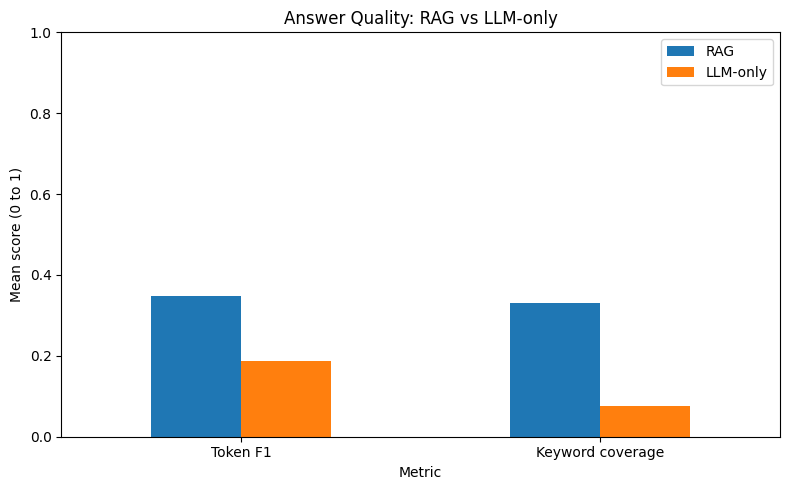

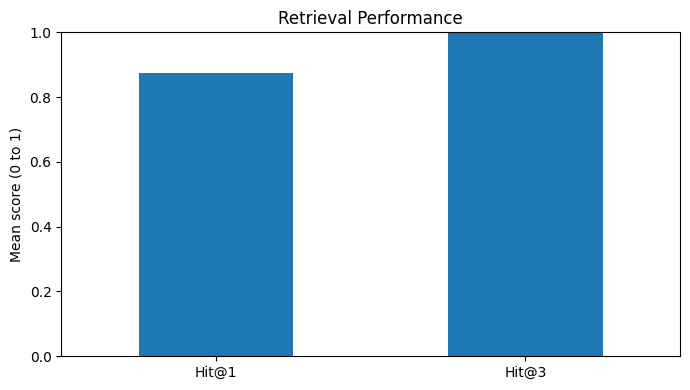

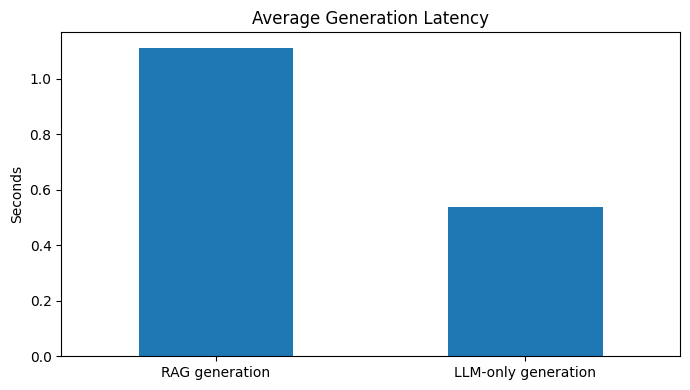

In [14]:
answer_scores = pd.DataFrame({
    "RAG": [
        evaluation_df["RAG token F1"].mean(),
        evaluation_df["RAG keyword coverage"].mean()
    ],
    "LLM-only": [
        evaluation_df["LLM-only token F1"].mean(),
        evaluation_df["LLM-only keyword coverage"].mean()
    ]
}, index=["Token F1", "Keyword coverage"])

ax = answer_scores.plot(kind="bar", figsize=(8, 5), ylim=(0, 1))
ax.set_title("Answer Quality: RAG vs LLM-only")
ax.set_ylabel("Mean score (0 to 1)")
ax.set_xlabel("Metric")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

retrieval_means = evaluation_df[["Hit@1", "Hit@3"]].mean()
plt.figure(figsize=(7, 4))
retrieval_means.plot(kind="bar")
plt.title("Retrieval Performance")
plt.ylabel("Mean score (0 to 1)")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

latency_means = pd.Series({
    "RAG generation": evaluation_df["RAG latency (s)"].mean(),
    "LLM-only generation": evaluation_df["LLM-only latency (s)"].mean()
})
plt.figure(figsize=(7, 4))
latency_means.plot(kind="bar")
plt.title("Average Generation Latency")
plt.ylabel("Seconds")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4.2 Manual evidence inspection

Automatic metrics cannot establish whether an answer is factually supported. Inspect the retrieved passages and generated answer. Check whether the answer addresses the question, includes relevant details, avoids unsupported claims and acknowledges missing information.

In [15]:
inspection_index = 0  # Select a value from 0 to 7.
case = evaluation_cases[inspection_index]
inspection = rag_pipeline(case["question"], top_k=3)

print("QUESTION:", case["question"])
print("\nREFERENCE ANSWER:", case["reference"])
print("\nRAG ANSWER:", inspection["answer"])
print("\nRETRIEVED EVIDENCE:")
for item in inspection["retrieved"]:
    print(f"\nSource: {item['source']} | similarity: {item['score']:.4f}")
    print(textwrap.fill(item["text"], width=105))

QUESTION: What are the main goals of inclusive development towards India 2047?

REFERENCE ANSWER: Inclusive development aims to expand economic opportunity and access to quality education, healthcare, clean water, sanitation, reliable energy and digital services across regions and communities.

RAG ANSWER: a prosperous, inclusive, capable and developed nation

RETRIEVED EVIDENCE:

Source: 01_vision_2047_and_inclusive_development.txt | similarity: 0.8277
Future India 2047 and inclusive development. India's development vision towards 2047 focuses on a
prosperous, inclusive, capable and developed nation. Development involves economic opportunity, quality
public services, infrastructure, innovation, environmental sustainability and citizen participation.
Inclusive development aims to ensure that opportunities reach people across regions, genders, income
groups and communities. Access to education, healthcare, skills, clean water, sanitation, reliable energy
and digital services supports hu

### 4.3 Missing-information test

This question asks for a specific future government budget allocation that is intentionally not stated in the educational notes. Similarity search always returns the nearest chunks, even if none contains the answer. Therefore, inspect the answer and evidence rather than treating a similarity score as proof that the information exists.

In [16]:
unknown_question = "What exact budget allocation will the Government of India announce for every Future India 2047 programme?"

unknown_result = rag_pipeline(unknown_question, top_k=3)
print("QUESTION:", unknown_question)
print("\nRAG RESPONSE:", unknown_result["answer"])
print("\nNEAREST RETRIEVED SOURCES:")
for item in unknown_result["retrieved"]:
    print(f"- {item['source']} | similarity={item['score']:.4f}")

QUESTION: What exact budget allocation will the Government of India announce for every Future India 2047 programme?

RAG RESPONSE: a digitally empowered society and knowledge economy

NEAREST RETRIEVED SOURCES:
- 01_vision_2047_and_inclusive_development.txt | similarity=0.6006
- 01_vision_2047_and_inclusive_development.txt | similarity=0.5288
- 02_digital_india_and_public_infrastructure.txt | similarity=0.3417


## 5. Application Demonstration

Use the function below to ask a new question about the Future India knowledge collection. It displays the RAG answer, retrieved source chunks and the LLM-only baseline.

In [17]:
def ask_future_india_rag(question, top_k=3):
    rag = rag_pipeline(question, top_k=top_k)
    baseline = llm_only_pipeline(question)

    print("=" * 90)
    print("QUESTION:", question)
    print("\nRAG ANSWER:\n", rag["answer"])
    print("\nRETRIEVED SOURCES:")
    for rank, item in enumerate(rag["retrieved"], start=1):
        print(
            f"{rank}. {item['source']} | chunk {item['chunk_number']} "
            f"| cosine similarity {item['score']:.4f}"
        )
    print("\nLLM-ONLY ANSWER:\n", baseline["answer"])
    print(f"\nRAG generation time: {rag['generation_time']:.2f} seconds")
    print(f"LLM-only generation time: {baseline['generation_time']:.2f} seconds")
    print("=" * 90)

demo_question = "How can clean energy and modern transport support India's development?"
ask_future_india_rag(demo_question, top_k=3)

QUESTION: How can clean energy and modern transport support India's development?

RAG ANSWER:
 reliable energy and digital services

RETRIEVED SOURCES:
1. 05_modern_transportation_and_logistics.txt | chunk 1 | cosine similarity 0.7300
2. 05_modern_transportation_and_logistics.txt | chunk 2 | cosine similarity 0.5818
3. 01_vision_2047_and_inclusive_development.txt | chunk 1 | cosine similarity 0.4911

LLM-ONLY ANSWER:
 clean energy and modern transport

RAG generation time: 0.80 seconds
LLM-only generation time: 0.28 seconds


## 6. Results and Discussion

Use the evaluation table and plots produced by the executed notebook. Do not insert assumed or fabricated values.

### 6.1 Implementation results

- Six topic-based Future India reference files are loaded and cleaned.
- The documents are split into overlapping chunks with source metadata.
- MiniLM generates normalized dense embeddings for all chunks.
- FAISS stores the vectors in an exact inner-product index.
- The retrieval function returns the top-k semantically similar chunks.
- FLAN-T5-small generates answers using retrieved context.
- The same model generates baseline answers without retrieval.
- Retrieval metrics, answer overlap metrics and generation latency are calculated.

### 6.2 Discussion guide

Hit@1, Hit@3 and MRR indicate whether the expected source document is retrieved near the top. Token F1 and keyword coverage indicate lexical overlap with the reference answers. Higher overlap may suggest closer agreement with the expected answer, but it does not prove factual correctness. Latency shows the measured generation time and may vary with hardware and runtime load.

RAG is expected to provide answers more closely tied to the supplied collection when relevant passages are retrieved. It can still fail if retrieval is poor, the reference collection lacks the answer or the LLM misinterprets the context. Discuss the actual results observed in your run.

## 7. Limitations

1. The local knowledge collection contains concise educational summaries, not complete government policy documents.
2. Programme details, targets, eligibility and budgets may change; verify current information from official sources.
3. Fixed word-based chunking is simple and reproducible, but structure-aware chunking may be better for long reports with tables and headings.
4. FAISS `IndexFlatIP` performs exact search and is suitable for a small corpus; larger deployments may require a persistent vector database and approximate indexing.
5. FLAN-T5-small may produce incomplete, repetitive or incorrect answers.
6. Similarity scores do not guarantee that a retrieved passage supports the answer.
7. Token F1 and keyword coverage measure lexical overlap, not semantic correctness or factual entailment.
8. The first run requires internet access to download the models. CPU inference may be slow.

## 8. Conclusion

A domain-specific Retrieval-Augmented Generation application was developed for the topic Future India 2047. Six topic-based reference documents covering inclusive development, digital infrastructure, smart cities, clean energy, transportation, healthcare, education and agriculture were loaded, cleaned and divided into overlapping chunks. A pre-trained MiniLM sentence-transformer generated dense embeddings, and FAISS indexed the vectors for semantic retrieval.

The retrieved passages were supplied to a pre-trained FLAN-T5-small model to generate context-aware answers. The same LLM was also evaluated without retrieval. Hit@k, MRR, token-level F1, keyword coverage and generation latency were used to compare the two approaches.

The practical demonstrates how RAG connects a language model to an external domain-specific knowledge collection. It can improve grounding in the selected documents, but its performance depends on document quality, chunking, retrieval relevance, prompt design and the language model.

## 9. References

1. NITI Aayog, *Strategy for New India @ 75* and national development policy resources. https://www.niti.gov.in/
2. Ministry of Electronics and Information Technology, *Digital India*. https://www.digitalindia.gov.in/
3. Ministry of Housing and Urban Affairs, *Smart Cities Mission*. https://smartcities.gov.in/
4. Ministry of New and Renewable Energy, *National Green Hydrogen Mission*. https://mnre.gov.in/
5. Ministry of Road Transport and Highways, Government of India. https://morth.nic.in/
6. Ministry of Health and Family Welfare, *Ayushman Bharat Digital Mission*. https://abdm.gov.in/
7. Ministry of Education, *National Education Policy 2020*. https://www.education.gov.in/nep/about-nep
8. Ministry of Agriculture and Farmers Welfare, Government of India. https://agriwelfare.gov.in/

## 10. Declaration

I, **Shreya Dattaram Bhosale**, confirm that the work submitted in this assignment is my own and has been completed following academic integrity guidelines.


**GitHub Repository Link:** https://github.com/bhosaleshreya25/Generative-AI/tree/main/Practical-6

**Signature:** Shreya Dattaram Bhosale